# Teaching NanoGPT to Do Math with DPO

SC3000/CZ3005 Assignment 1

**Team and contributions:** *(to fill in before submission: team name, members, and what each member did. The manual asks for this when a team has more than one member.)*

## Overview

The model is a small character-level NanoGPT (8.8M parameters) pretrained on question-answer chat data. Before fine-tuning, it answers arithmetic questions with "Sorry, I don't know." We fine-tune it with DPO (Direct Preference Optimization). For each question the training data holds a preferred reply (the *positive*, a correct answer with its working) and a rejected reply (the *negative*, the pretrained model's own refusal). The loss makes the positive more likely than the negative.

| Task | Where | Result |
|---|---|---|
| Task 1: build positive-negative pairs | the "Task 1" section after Step 4 | `pos_neg_pairs.json`, 100,201 pairs |
| Task 2: fine-tune with DPO | Steps 5–7 | `dpo.pt` |
| Task 3: test the fine-tuned model | Step 8 | answers to the test set, accuracy on 600 held-out questions |
| Task 4: explanation and analysis | the text cells, and an ablation at the end | |

**How to run.** Start Jupyter from the `dpo/` folder, because the code uses relative paths such as `../sft/gpt.pt` and `../model.py`. Then run the cells from top to bottom. On an Apple M2 Pro laptop GPU (MPS), Task 1 takes about 22 minutes, training about 86 minutes, and the ablation at the end about 183 minutes. The ablation is optional: Tasks 1–3 do not depend on it. A CUDA GPU is faster.

**To test the submitted `dpo.pt` only** (without rebuilding the data or retraining): run Steps 1–4 and the first Task 1 cell, skip the second Task 1 cell (the one that calls `main`) and Steps 5–7, then run Step 8 and stop there: the ablation after it needs Step 7.

**Changes to the provided template** (each one is explained where it happens):
- Step 1 installs packages with `%pip` instead of `!pip`.
- Step 2 also uses Apple's GPU (`mps`), drops the `CUDA_VISIBLE_DEVICES = "1"` line, sets `max_length = 80`, and uses learning rate `1e-3` and 12 epochs instead of `1e-4` and 5.
- Step 7 scores only the reply part of each sequence (`compute_reply_logprob`) instead of the whole sequence, and checks the held-out accuracy after every epoch. The ablation at the end shows that this does not help: the template's scoring learns faster and ends at the same accuracy.
- Step 8 uses `.to(device)` instead of `.cuda()`, so it also runs without an NVIDIA GPU.

### Step 1: Install necessary packages

`%pip` installs into the environment of the running kernel. `!pip` runs whichever `pip` comes first on the shell's PATH, which can belong to a different Python. Only `torch`, `numpy`, `matplotlib` and `tqdm` are used below; the other packages are kept from the template.

In [1]:
%pip install matplotlib
%pip install torch numpy transformers datasets tiktoken wandb tqdm

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Step 2: Package imports and configuration

Changes from the template:
- **Device.** The template only checks for CUDA. We also use Apple's GPU (`mps`) when there is one, and fall back to the CPU otherwise.
- **`CUDA_VISIBLE_DEVICES = "1"` removed.** That line hides every GPU except the second one. On a machine with a single GPU, PyTorch would then see no GPU at all and silently train on the CPU.
- **`max_length = 80` instead of 64.** The longest positive in our data is 70 characters, counting the 4 newlines that `get_batches` adds. `pad_or_truncate` keeps the *last* `max_length` characters, so with 64, 653 positives would lose the start of their question. Only 3 negatives are longer than 80: rambling replies of the pretrained model (see Task 1).
- **Learning rate `1e-3` instead of `1e-4`, and 12 epochs instead of 5.** In a one-epoch trial run with the template's `1e-4`, the model learned the sentence pattern but answered only 1.7% of the test questions correctly: it still guessed the answer digits. Learning the arithmetic itself is the slow part, so we raised the learning rate and trained for longer. With these settings the accuracy also stays low at first, for three epochs, and then jumps in the fourth; Step 7 prints it after every epoch. We did not test whether `1e-4` with 12 epochs would do as well.
- `re` and `Counter` are imported for Task 1 and Step 8.

The other settings are the template's: `beta = 0.5`, batch size 64, and the sampling settings for `gpt.generate` (temperature 0.8, top_k 200, at most 200 new characters).

The tokenizer works on single characters: `meta.pkl` maps each of the 74 characters to an id. The newline character has id 0, which is also used for padding, and `.` has id 7. `gpt.generate` in `model.py` stops at either of these two.

In [2]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import pickle
from model import GPT, GPTConfig
from tqdm import tqdm
import time
import json
import re
from collections import Counter
import matplotlib.pyplot as plt
# Configuration
beta = 0.5
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print("device: ", device)
base_lr = 1e-3
epochs = 12
batch_size = 64
max_length = 80
num_samples = 1
max_new_tokens = 200
temperature = 0.8
top_k = 200
# tokenizer
with open("../sft/meta.pkl", "rb") as f:
    meta = pickle.load(f)
stoi, itos = meta["stoi"], meta["itos"]
def encode(s): return [stoi[c] for c in s]
def decode(l): return ''.join([itos[i] for i in l])

device:  mps


### Step 3: Define helper functions

These three functions come with the template and are used unchanged:
- `compute_logprob(input_ids)` runs the model on each sequence and returns the **average log-probability per character**, leaving out padding (id 0). For a batch of `B` sequences it returns a tensor of shape `B`. Step 7 uses a variant that scores only the reply.
- `pad_or_truncate(seq, max_length)` pads a sequence with id 0 up to `max_length`. A longer sequence keeps only its last `max_length` ids.
- `get_batches(lines, batch_size)` shuffles the pairs, appends 4 newlines to each negative and positive, encodes and pads them, and yields `(neg_tensor, pos_tensor)`, each of shape `batch_size × max_length`. The last incomplete batch is dropped.

Because the newline is id 0, the 4 newlines appended in `get_batches` are treated as padding and never scored. The model therefore learns to end a reply with `.`, which is also where `gpt.generate` stops.

In [3]:
def compute_logprob(input_ids):
    inputs = input_ids[:, :-1]
    targets = input_ids[:, 1:]
    logits, _ = gpt(inputs, full_seq=True)
    B, T, V = logits.size()
    logits_flat = logits.reshape(-1, V)
    targets_flat = targets.reshape(-1)
    loss = F.cross_entropy(logits_flat, targets_flat, ignore_index=0, reduction='none')
    loss = loss.reshape(B, T)
    attention_mask = (targets != 0).float()
    loss = (loss * attention_mask).sum(dim=1) / attention_mask.sum(dim=1)
    return -loss 

def pad_or_truncate(seq, max_length):
    return seq[-max_length:] if len(seq) > max_length else seq + [0] * (max_length - len(seq))

def get_batches(lines, batch_size):
    random.shuffle(lines)
    #for l in lines:
    #    print(l[1])
    for i in range(0, len(lines), batch_size):
        batch = lines[i:i+batch_size]
        if len(batch) < batch_size:
            continue
        neg_inputs = [pad_or_truncate(encode(p['negative'] + '\n\n\n\n'), max_length) for p in batch]
        pos_inputs = [pad_or_truncate(encode(p['positive'] + '\n\n\n\n'), max_length) for p in batch]
        neg_tensor = torch.tensor(neg_inputs, dtype=torch.long, device=device)
        pos_tensor = torch.tensor(pos_inputs, dtype=torch.long, device=device)
        yield neg_tensor, pos_tensor

### Step 4: Load the pretrained NanoGPT model

This loads `sft/gpt.pt`: 6 layers, 6 attention heads, 348-dimensional embeddings, a context of 256 characters and a 74-character vocabulary, 8.8M parameters in total. The `_orig_mod.` prefix that `torch.compile` adds to the weight names is removed before loading. The model is left in training mode, so dropout (p = 0.2) is on.

The cell after it shows what the pretrained model says before any fine-tuning. It answers ordinary questions but refuses arithmetic.

In [4]:
ckpt = torch.load("../sft/gpt.pt", map_location=device)
gptconf = GPTConfig(**ckpt['model_args'])
gpt = GPT(gptconf)
state_dict = ckpt['model']
unwanted_prefix = '_orig_mod.'
for k in list(state_dict.keys()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
gpt.to(device).train()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(74, 348)
    (wpe): Embedding(256, 348)
    (drop): Dropout(p=0.2, inplace=False)
    (h): ModuleList(
      (0-5): 6 x Block(
        (ln_1): LayerNorm()
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=348, out_features=1044, bias=False)
          (c_proj): Linear(in_features=348, out_features=348, bias=False)
          (attn_dropout): Dropout(p=0.2, inplace=False)
          (resid_dropout): Dropout(p=0.2, inplace=False)
        )
        (ln_2): LayerNorm()
        (mlp): MLP(
          (c_fc): Linear(in_features=348, out_features=1392, bias=False)
          (gelu): GELU(approximate='none')
          (c_proj): Linear(in_features=1392, out_features=348, bias=False)
          (dropout): Dropout(p=0.2, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm()
  )
  (lm_head): Linear(in_features=348, out_features=74, bias=False)
)

In [5]:
# What the pretrained model says before fine-tuning
gpt.eval()
for prompt in ["What's your name?", "17+19=?", "x*11=44,x=?"]:
    x = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
    print(decode(y[0].tolist()))
gpt.train();          # back to training mode; the ";" stops Jupyter from printing the model again

What's your name? My name is John
17+19=? Sorry, I don't know.
x*11=44,x=? Sory, I don't know.


### Task 1: Build positive-negative data pairs

This cell builds 100,201 (negative, positive) pairs and saves them to `./pos_neg_pairs.json` (that is, `dpo/pos_neg_pairs.json`), in the same format as the sample file. Step 5 loads this file.

**Question types.** There are 12 types: the four operations asked directly (`a+b=?`, `a-b=?`, `a*b=?`, `a/b=?`), and each operation as an equation with `x` on the left (`x+a=b,x=?`) or on the right (`a+x=b,x=?`). The format copies the Step 8 test set exactly, with no space after the comma, because the model reads one character at a time.

**Numbers.** For each type we draw two numbers from 0–100 and work out the third from them, so the answer is always a whole number. For example, for `a/b=?` we draw `b` and the answer, then set `a = b*answer`. A pair is skipped if it would divide by 0, give a negative answer, or give an equation with more than one solution (such as `0*x=0`). For each type we list every allowed pair and shuffle them. The first 50 are kept aside as **held-out questions**: these exact questions are never trained on, and Step 8 measures accuracy on them. The same arithmetic fact can still appear in training in another form, for example `83*86=?` for a held-out `86*83=?`. The next 9000 become training pairs. The two subtraction types only have about 5150 allowed pairs each, so the total is 100,201 training pairs. The 5 questions of the Step 8 test set are left out of the training data in the same way.

**Positive.** The same wording as the sample file: `79-7=? The answer is 72 because 79-7 equals 72.` for plain calculations, and `x+55=95,x=? The answer is 40 because 95-55 equals to 40.` for equations, where the working after "because" is the reverse operation.

**Negative.** The pretrained model's own reply to the question, sampled the same way as `gpt.generate` (temperature 0.8, top_k 200, stop at `.` or a newline). Calling `gpt.generate` once per question takes about 0.1 s, which is about 3 hours for 100k questions. Instead, `make_negative` answers up to 1024 questions of the same length at once (same length means no padding is needed); this took 22 minutes here. On a Mac, PyTorch keeps growing its GPU memory cache when the input length changes at every step, as it does here. In one of our runs it grew to 15 GB and the machine slowed to a crawl, so `sample_replies` empties the cache after every batch.

**Output.** The pretrained model refuses almost every question: 64,605 replies are "Sorry, I don't know.", 26,737 are the misspelling "Sory, I don't know." and 5,915 are "I don't know.", so 97% of the negatives are one of these three. The rest are rarer variants and a few off-topic replies, such as "I like pizza" in the example pairs. The longest positive is 70 characters, and 653 positives are longer than 64, which is why Step 2 sets `max_length = 80`. Only 3 negatives are longer than 80 (the longest is 211 characters): replies where the pretrained model kept on talking. `pad_or_truncate` cuts their start in training.

**Checking answers.** `reply_is_correct` takes the number after "The answer is" in a reply, puts it back into the question and checks the arithmetic. The question is passed in separately, so only our own question string and one whole number from the reply ever reach `eval`. `heldout_accuracy` uses it to score the current model on all held-out questions. Step 7 and the ablation call `heldout_accuracy`; Step 8 calls `reply_is_correct` directly. If a question has a format the checker does not know, `reply_is_correct` returns `None` instead of failing.

**Two cells.** The first cell builds the questions and positives and defines all functions; it runs in a second. The second cell calls `main`, which generates the negatives and writes `pos_neg_pairs.json`; it is the slow one.

**Reproducibility.** The seed makes the questions and positives the same on every machine. The negatives also depend on the device's random number generator, so running this cell on another device gives slightly different negatives and overwrites `pos_neg_pairs.json`.

In [6]:
random.seed(0)
torch.manual_seed(0)
numbers = range(0, 101)
max_per_type = 9000            # training questions per type
heldout_per_type = 50          # questions per type kept out of training, used in Step 8
data_path = "./pos_neg_pairs.json"
test_prompts = {"17+19=?", "3*17=?", "72/4=?", "72-x=34,x=?", "x*11=44,x=?"}  # the Step 8 test set
newline_id = stoi["\n"]
period_id = stoi["."]

# The 12 question types. Each function takes two numbers drawn from 0..100 and returns
# (question, answer, working), where `working` is the calculation written after "because",
# or None when the pair is not allowed.
def add(a, b):    return f"{a}+{b}=?", a + b, f"{a}+{b}"
def sub(a, b):    return (f"{a}-{b}=?", a - b, f"{a}-{b}") if b <= a else None
def mul(a, b):    return f"{a}*{b}=?", a * b, f"{a}*{b}"
def div(b, q):    return (f"{b*q}/{b}=?", q, f"{b*q}/{b}") if b > 0 else None

def x_add(x, a):  return f"x+{a}={x+a},x=?", x, f"{x+a}-{a}"
def add_x(x, a):  return f"{a}+x={a+x},x=?", x, f"{a+x}-{a}"
def x_sub(a, b):  return f"x-{a}={b},x=?", a + b, f"{b}+{a}"
def sub_x(a, x):  return (f"{a}-x={a-x},x=?", x, f"{a}-{a-x}") if x <= a else None
def x_mul(x, a):  return (f"x*{a}={x*a},x=?", x, f"{x*a}/{a}") if a > 0 else None
def mul_x(x, a):  return (f"{a}*x={a*x},x=?", x, f"{a*x}/{a}") if a > 0 else None
def x_div(a, b):  return (f"x/{a}={b},x=?", a * b, f"{b}*{a}") if a > 0 else None
def div_x(x, b):  return (f"{x*b}/x={b},x=?", x, f"{x*b}/{b}") if x > 0 and b > 0 else None


question_types = [add, sub, mul, div, x_add, add_x, x_sub, sub_x, x_mul, mul_x, x_div, div_x]

def build_questions(make):
    """Collect every allowed question of one type, in random order."""
    items = []
    for p in numbers:
        for q in numbers:
            item = make(p, q)
            if item is None:                  # this pair of numbers is not allowed
                continue
            question = item[0]
            if question in test_prompts:      # keep the test questions out of the training data
                continue
            items.append(item)
    random.shuffle(items)
    return items


def make_positive(question, answer, working):
    """Write the positive reply for one question: the question, the answer and its working."""
    # The sample file dpo/pos_neg_pairs.json (Figure 4) writes "equals" for plain calculations
    # and "equals to" for equations with x, so we use the same wording.
    if "x" in question:
        link = "equals to"
    else:
        link = "equals"
    return f"{question} The answer is {answer} because {working} {link} {answer}."

questions = []
positives = []
heldout_items = []             # (question, answer, working), never used for training
for make in question_types:
    items = build_questions(make)
    heldout_items += items[:heldout_per_type]
    for question, answer, working in items[heldout_per_type:heldout_per_type + max_per_type]:
        questions.append(question)
        positives.append(make_positive(question, answer, working))
print("Number of training questions:", len(questions))
print("Number of held-out questions:", len(heldout_items))
print("Example positive:", positives[0])

@torch.no_grad()
def make_negative(batch):
    """Let the model answer a batch of questions that all have the same length.

    The sampling steps follow GPT.generate in model.py: each question gets its own sampled
    characters, with the same temperature, top_k and stopping rules. The only difference
    is that the whole batch goes through the model at once. A question that has already finished keeps getting
    characters until the whole batch is done, and cut_reply removes them afterwards.
    """
    idx = torch.tensor([encode(question) for question in batch], dtype=torch.long, device=device)
    finished = torch.zeros(len(batch), dtype=torch.bool, device=device)
    for _ in range(max_new_tokens):
        logits, _ = gpt(idx)
        logits = logits[:, -1, :] / temperature
        # only keep the top_k most likely characters
        top_values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
        logits[logits < top_values[:, [-1]]] = -float("inf")
        probs = F.softmax(logits, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, next_id), dim=1)
        # a reply is finished once it has produced a newline or '.'
        finished = finished | (next_id[:, 0] == newline_id) | (next_id[:, 0] == period_id)
        if finished.all():
            break

    question_len = len(batch[0])
    negatives = []
    for question, row in zip(batch, idx.tolist()):
        reply = cut_reply(row[question_len:])
        negatives.append(question + reply)
    return negatives

def cut_reply(token_ids):
    """Keep the reply up to the first '.' (kept) or newline (dropped), the same rule as gpt.generate."""
    reply = []
    for t in token_ids:
        if t == newline_id:
            break
        reply.append(t)
        if t == period_id:
            break
    return decode(reply)

def group_by_length(questions):
    """Put questions of the same length together, so a batch can go into the model without padding."""
    groups = {}
    for question in questions:
        length = len(question)
        if length not in groups:
            groups[length] = []
        groups[length].append(question)
    return groups

def sample_replies(questions, generation_batch=1024):
    """Let the current model answer every question; returns {question: question + reply}.

    generation_batch is how many questions are answered at once (not the training batch_size).
    """
    reply_of = {}
    for same_length in tqdm(group_by_length(questions).values(), desc="question-length groups"):
        for i in range(0, len(same_length), generation_batch):
            batch = same_length[i:i + generation_batch]
            for question, text in zip(batch, make_negative(batch)):
                reply_of[question] = text
            if device == "mps":
                torch.mps.empty_cache()   # otherwise the GPU memory cache keeps growing on a Mac
    return reply_of

def main(questions, positives, path):
    """Let the pretrained model answer every question, then save the (negative, positive) pairs to `path`."""
    start = time.time()
    gpt.eval()                    # no dropout while sampling
    try:
        negative_of = sample_replies(questions)
    finally:
        gpt.train()               # back to training mode for Step 7, even if this cell is stopped halfway
    print(f"Generated {len(negative_of)} negatives in {(time.time() - start) / 60:.1f} minutes")

    pairs = []
    for question, positive in zip(questions, positives):
        pairs.append({"negative": negative_of[question], "positive": positive})
    with open(path, "w", encoding="utf-8") as f:
        json.dump(pairs, f, ensure_ascii=False, indent=1)
    print(f"Saved {len(pairs)} pairs to {path}")

    reply_counts = Counter()
    for question in questions:
        reply_counts[negative_of[question][len(question):]] += 1
    print("Most common negative replies:")
    for reply, count in reply_counts.most_common(5):
        print(f"  {count:6d}  {reply!r}")

    # Lengths as get_batches sees them (it adds 4 newlines), to check max_length in Step 2
    positive_lengths = [len(positive) + 4 for positive in positives]
    negative_lengths = [len(negative_of[question]) + 4 for question in questions]
    print(f"Longest positive: {max(positive_lengths)} characters; positives longer than 64: {sum(n > 64 for n in positive_lengths)}")
    print(f"Longest negative: {max(negative_lengths)} characters; negatives longer than max_length = {max_length}: {sum(n > max_length for n in negative_lengths)}")
    print("Some example pairs:")
    for pair in random.sample(pairs, 5):
        print(pair)

def reply_is_correct(question, text):
    """Put the number after "The answer is" in the model's text back into the question and check the arithmetic.

    Returns True or False, or None if the question has a format this checker does not know.
    """
    match = re.search(r"The answer is (\d+)", text[len(question):])
    if match is None:
        return False
    answer = str(int(match.group(1)))                       # "06" -> "6", so it can go into eval
    try:
        if "x" in question:                                  # "x+55=95,x=?" -> 40+55 == 95
            left, right = question.split(",")[0].replace("x", answer).split("=")
            return eval(left) == eval(right)
        return eval(question[:-2]) == int(answer)           # "79-7=?" -> 79-7 == 72
    except ZeroDivisionError:                                # e.g. answering 0 to "84/x=7,x=?"
        return False
    except (SyntaxError, NameError, TypeError, ValueError):  # a question format this checker does not know
        return None

heldout_questions = [question for question, answer, working in heldout_items]

def heldout_accuracy():
    """Answer the held-out questions with the current model; returns (share correct, {question: reply})."""
    gpt.eval()
    reply_of = sample_replies(heldout_questions)
    gpt.train()
    correct = 0
    for question in heldout_questions:
        if reply_is_correct(question, reply_of[question]):
            correct += 1
    return correct / len(heldout_questions), reply_of

def question_type(question):
    return re.sub(r"\d+", "n", question)          # "x+55=95,x=?" -> "x+n=n,x=?"

Number of training questions: 100201
Number of held-out questions: 600
Example positive: 91+46=? The answer is 137 because 91+46 equals 137.


In [7]:
# Generate the negatives with the pretrained model and save all pairs (about 30 minutes on an Apple M2 Pro).
# To test the submitted dpo.pt without rebuilding the data, skip this cell (see "How to run" at the top).
main(questions, positives, data_path)

question-length groups: 100%|██████████| 11/11 [21:47<00:00, 118.85s/it]


Generated 100201 negatives in 21.8 minutes
Saved 100201 pairs to ./pos_neg_pairs.json
Most common negative replies:
   64605  " Sorry, I don't know."
   26737  " Sory, I don't know."
    5915  " I don't know."
     303  " I Sorry, I don't know."
     198  " Sorrry, I don't know."
Longest positive: 70 characters; positives longer than 64: 653
Longest negative: 211 characters; negatives longer than max_length = 80: 3
Some example pairs:
{'negative': "20*74=? Sorry, I don't know.", 'positive': '20*74=? The answer is 1480 because 20*74 equals 1480.'}
{'negative': 'x/10=40,x=? I like pizza', 'positive': 'x/10=40,x=? The answer is 400 because 40*10 equals to 400.'}
{'negative': "76*56=? Sorry, I don't know.", 'positive': '76*56=? The answer is 4256 because 76*56 equals 4256.'}
{'negative': "12+x=30,x=? Sorry, I don't know.", 'positive': '12+x=30,x=? The answer is 18 because 30-12 equals to 18.'}
{'negative': "97-50=? Sorry, I don't know.", 'positive': '97-50=? The answer is 47 because 97-50 

### Step 5: Load Data

We load the file written by Task 1. The template comment mentions `./data/pos_neg_pairs.json`, but there is no `data/` folder; the file the manual asks us to submit is `dpo/pos_neg_pairs.json`, which is `data_path` here. The list is called `lines` because `get_batches` in Step 7 expects that name.

In [8]:
# Load the pairs built in Task 1
with open(data_path, encoding="utf-8") as f:
    lines = json.load(f)
print("Number of pairs:", len(lines))
print("Example pair:", lines[0])

Number of pairs: 100201
Example pair: {'negative': "91+46=? Sory, I don't know.", 'positive': '91+46=? The answer is 137 because 91+46 equals 137.'}


### Step 6: Build the optimizer and scheduler

- **AdamW**, as the template recommends, with the learning rate `base_lr = 1e-3` from Step 2 and a small weight decay (0.01).
- **Cosine schedule.** The learning rate starts at `1e-3` and falls along a cosine curve to `1e-4` at the last step. Large steps early on get the model through the slow first phase of learning arithmetic; small steps at the end let it settle on exact digits.
- With 100,201 pairs and a batch size of 64 there are 1,565 steps per epoch, 18,780 in total.

In [9]:
# recommend to use the AdamW optimizer
optimizer = torch.optim.AdamW(gpt.parameters(), lr=base_lr, weight_decay=0.01)

# The learning rate goes from base_lr down to base_lr/10 along a cosine curve over the whole training run
steps_per_epoch = len(lines) // batch_size      # get_batches drops the last incomplete batch
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * steps_per_epoch, eta_min=base_lr / 10)
print("Training steps:", epochs * steps_per_epoch)

Training steps: 18780


### Step 7: Begin training

**Loss.** We use the loss suggested in the template:

$$\text{loss} = -\log\sigma\!\left(\frac{\log p(\text{pos}) - \log p(\text{neg})}{\beta}\right) - 0.1\,\log p(\text{pos})$$

The first term is the DPO preference loss, and the second is an SFT (supervised fine-tuning) loss on the positive reply. Here $\log p(\cdot)$ is the average log-probability per character of a reply, computed by `compute_reply_logprob` (it scores only the reply; the ablation at the end compares it with the template's `compute_logprob`), and $\beta = 0.5$.

**Held-out check after every epoch.** The loss only shows how closely the model copies the training replies, not whether it can really calculate. So after every epoch the model answers the 600 held-out questions from Task 1, which it never trains on, and we print how many it gets right, along with one example reply for six of the question types. This shows when the model moves from copying the sentence pattern to actually calculating, and whether more epochs still help.

**Other details.** The random seeds are reset just before training, so the ablation can repeat this exact run (same batch order) with the other scoring function. Gradients are clipped to a norm of 1.0, so a single unusual batch cannot move the model too far. The progress bar shows the current loss. The checkpoint `dpo.pt` is saved after every epoch, as in the template.

In [10]:
space_id = stoi[" "]

def compute_reply_logprob(input_ids):
    """Like compute_logprob in Step 3, but only the reply is scored, not the question.

    We expected scoring the question to add only noise, since it is the same in the positive and
    the negative; the ablation at the end shows that scoring the whole sequence learns faster.
    The questions contain no spaces, so the reply starts at the first space.
    """
    inputs = input_ids[:, :-1]
    targets = input_ids[:, 1:]
    logits, _ = gpt(inputs, full_seq=True)
    B, T, V = logits.size()
    token_loss = F.cross_entropy(logits.reshape(-1, V), targets.reshape(-1), reduction="none").reshape(B, T)

    # targets[:, t] is the character at position t+1, so the reply starts at t = reply_start - 1
    reply_start = (input_ids == space_id).float().argmax(dim=1)
    positions = torch.arange(T, device=input_ids.device)
    is_reply = positions[None, :] >= (reply_start[:, None] - 1)
    mask = (is_reply & (targets != 0)).float()     # id 0 is the padding
    return -(token_loss * mask).sum(dim=1) / mask.sum(dim=1)

random.seed(0)                 # fixed batch order and dropout, so the ablation can repeat this run
torch.manual_seed(0)
loss_history = []
accuracy_history = []          # held-out accuracy after each epoch
start = time.time()
total_steps = len(lines) // batch_size
for epoch in range(epochs):
    pbar = tqdm(get_batches(lines, batch_size), total=total_steps)
    for step, (neg_tensor, pos_tensor) in enumerate(pbar):
        neg_logprob = compute_reply_logprob(neg_tensor)
        pos_logprob = compute_reply_logprob(pos_tensor)
        # DPO part: make the positive more likely than the negative.
        # SFT part (- 0.1 * pos_logprob): also raise the probability of the positive directly.
        loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean() - pos_logprob.mean() * 0.1

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        loss_history.append(loss.item())
        pbar.set_description(f"epoch {epoch + 1}/{epochs}, loss {loss.item():.3f}")
    ckpt_path = f"./dpo.pt"
    torch.save({
        "model_state_dict": gpt.state_dict(),
        "model_args": ckpt['model_args'],
    }, ckpt_path)
    epoch_loss = sum(loss_history[-total_steps:]) / total_steps
    accuracy, reply_of = heldout_accuracy()
    accuracy_history.append(accuracy)
    print(f"Epoch {epoch + 1}: average loss {epoch_loss:.4f}, held-out accuracy {accuracy:.1%}. Saved checkpoint to {ckpt_path}")
    for question in heldout_questions[::100]:     # one held-out reply each for a+b, a*b, x+a=b, x-a=b, x*a=b, x/a=b
        print("   ", reply_of[question])
print(f"Training took {(time.time() - start) / 60:.1f} minutes")

question-length groups: 100%|██████████| 9/9 [00:14<00:00,  1.58s/it]


Epoch 1: average loss 0.0432, held-out accuracy 1.7%. Saved checkpoint to ./dpo.pt
    77+98=? The answer is 87 because 77+98 equals 87.
    86*83=? The answer is 4897 because 86*83 equals 4897.
    x+19=100,x=? The answer is 80 because 100-19 equals to 80.
    x-4=88,x=? The answer is 80 because 88+4 equals to 80.
    x*62=6076,x=? The answer is 79 because 6076/62 equals to 79.
    x/76=11,x=? The answer is 4458 because 11*76 equals to 4548.


question-length groups: 100%|██████████| 9/9 [00:13<00:00,  1.55s/it]


Epoch 2: average loss 0.0135, held-out accuracy 3.0%. Saved checkpoint to ./dpo.pt
    77+98=? The answer is 125 because 77+98 equals 125.
    86*83=? The answer is 3122 because 86*83 equals 3122.
    x+19=100,x=? The answer is 47 because 100-19 equals to 47.
    x-4=88,x=? The answer is 80 because 88+4 equals to 80.
    x*62=6076,x=? The answer is 86 because 6076/62 equals to 86.
    x/76=11,x=? The answer is 593 because 11*76 equals to 593.


question-length groups: 100%|██████████| 9/9 [00:14<00:00,  1.61s/it]


...

Epoch 10: average loss 0.0019, held-out accuracy 80.8%. Saved checkpoint to ./dpo.pt
    77+98=? The answer is 175 because 77+98 equals 175.
    86*83=? The answer is 7118 because 86*83 equals 7118.
    x+19=100,x=? The answer is 81 because 100-19 equals to 81.
    x-4=88,x=? The answer is 92 because 88+4 equals to 92.
    x*62=6076,x=? The answer is 98 because 6076/62 equals to 98.
    x/76=11,x=? The answer is 856 because 11*76 equals to 856.


question-length groups: 100%|██████████| 9/9 [00:14<00:00,  1.64s/it]


Epoch 11: average loss 0.0017, held-out accuracy 81.3%. Saved checkpoint to ./dpo.pt
    77+98=? The answer is 175 because 77+98 equals 175.
    86*83=? The answer is 7458 because 86*83 equals 7458.
    x+19=100,x=? The answer is 81 because 100-19 equals to 81.
    x-4=88,x=? The answer is 92 because 88+4 equals to 92.
    x*62=6076,x=? The answer is 98 because 6076/62 equals to 98.
    x/76=11,x=? The answer is 816 because 11*76 equals to 816.


question-length groups: 100%|██████████| 9/9 [00:14<00:00,  1.60s/it]

Epoch 12: average loss 0.0015, held-out accuracy 83.2%. Saved checkpoint to ./dpo.pt
    77+98=? The answer is 175 because 77+98 equals 175.
    86*83=? The answer is 7998 because 86*83 equals 7998.
    x+19=100,x=? The answer is 81 because 100-19 equals to 81.
    x-4=88,x=? The answer is 92 because 88+4 equals to 92.
    x*62=6076,x=? The answer is 98 because 6076/62 equals to 98.
    x/76=11,x=? The answer is 816 because 11*76 equals to 816.
Training took 85.7 minutes


#### Training curve

The accuracy and the example replies printed after each epoch show two phases.

- **Epochs 1–3: the model learns the sentence, not the arithmetic.** Within the first few hundred steps the loss falls from about 14 to a few hundredths: the model stops refusing and writes replies of the form "The answer is … because … equals …". After epoch 1, all six example replies already copy the numbers of the question into the working and turn each equation into the right calculation (`x+19=100` becomes `100-19`, `x/76=11` becomes `11*76`), but the answers themselves are guessed. Held-out accuracy is 1.7%, 3.0% and 9.0% after epochs 1, 2 and 3.
- **From epoch 4: the model learns to calculate.** Accuracy jumps to 35.0% after epoch 4 and 50.0% after epoch 5, then rises more slowly as the learning rate decays, to 83.2% after the last epoch. The examples `77+98=?` and `x+19=100,x=?` are right from epoch 4 on, and `x-4=88,x=?` from epoch 6 on. The product `86*83=?` (7138) is never right; the closest answers are 7118 after epoch 10 and 7098 after epoch 7.

The jump also shows in the loss. On the log scale, the loss stays near 0.01 from about step 2,500 to step 5,000 and then bends down, in epoch 4 (steps 4,696–6,260), when the accuracy jumps; the epoch-average loss falls from 0.0111 after epoch 3 to 0.0055 after epoch 5. Once the fixed wording of the reply has been learned, most of the remaining loss comes from the answer digits, so learning them is what drives the loss down.

Accuracy rose in every epoch, so the long training did not hurt on these questions. The numbers still carry sampling noise: with 600 questions, one standard error is about 1.6 percentage points. The same final model scores 83.2% here and 80.3% in Step 8, where the questions are answered again with new random samples. The example `x*62=6076,x=?` shows the same noise: it is right after epochs 7 and 9–12, but answered 92 instead of 98 after epoch 8.

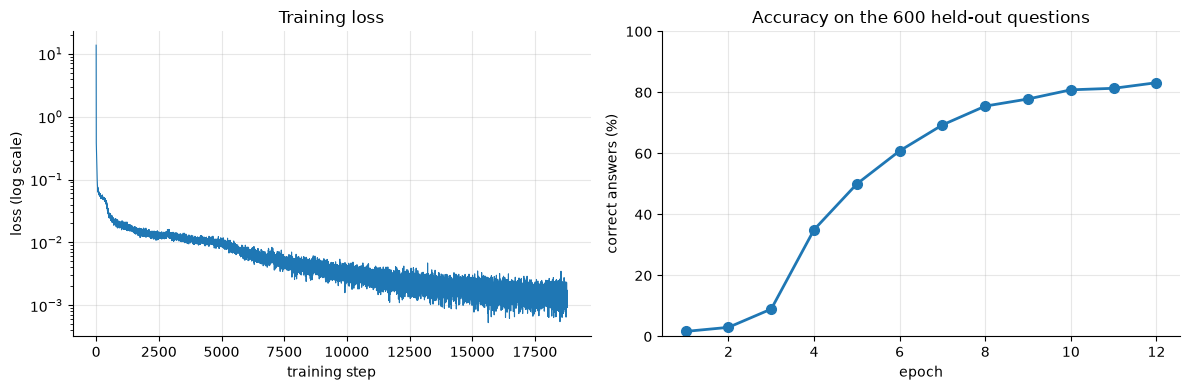

In [11]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(loss_history, linewidth=0.8)
ax_loss.set_yscale("log")                      # the loss falls from about 14 to about 0.001
ax_loss.set_xlabel("training step")
ax_loss.set_ylabel("loss (log scale)")
ax_loss.set_title("Training loss")
epochs_done = range(1, len(accuracy_history) + 1)
ax_acc.plot(epochs_done, [100 * a for a in accuracy_history], linewidth=2, marker="o", markersize=7)
ax_acc.set_xlabel("epoch")
ax_acc.set_ylabel("correct answers (%)")
ax_acc.set_ylim(0, 100)
ax_acc.set_title("Accuracy on the 600 held-out questions")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Step 8: Begin testing

The template code loads `dpo.pt` into a new model. The only change is `.to(device)` instead of `.cuda()`, so it also runs on a Mac or a CPU. Each test prompt goes through `gpt.generate` with the template's sampling settings, and we print the reply, marked `correct` or `WRONG` by `reply_is_correct` (Task 1), or `?` if the question has a format the checker does not know.

In [12]:
# Load the fine-tuned model
ckpt_path = "../dpo/dpo.pt"
checkpoint = torch.load(ckpt_path, map_location=device)
gptconf = GPTConfig(**checkpoint['model_args'])
gpt = GPT(gptconf).to(device)
try:
    state_dict = checkpoint['model']
except:
    state_dict = checkpoint['model_state_dict']
unwanted_prefix = '_orig_mod.'
for k,v in list(state_dict.items()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
# Test
gpt.eval()
test_set = ["17+19=?", "3*17=?", "72/4=?", "72-x=34,x=?", "x*11=44,x=?", "3*17=?", "72/4=?", "72-x=34,x=?"]
with torch.no_grad():
    for prompt in test_set:
        prompt_ids = encode(prompt)
        x = torch.tensor([prompt_ids], dtype=torch.long, device=device)
        y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
        reply = decode(y[0].tolist())
        result = reply_is_correct(prompt, reply)
        if result is None:
            print("?       |", reply)          # the checker does not know this question format
        elif result:
            print("correct |", reply)
        else:
            print("WRONG   |", reply)

correct | 17+19=? The answer is 36 because 17+19 equals 36.
correct | 3*17=? The answer is 51 because 3*17 equals 51.
correct | 72/4=? The answer is 18 because 72/4 equals 18.
correct | 72-x=34,x=? The answer is 38 because 72-34 equals to 38.
correct | x*11=44,x=? The answer is 4 because 44/11 equals to 4.
WRONG   | 3*17=? The answer is 41 because 3*17 equals 41.
correct | 72/4=? The answer is 18 because 72/4 equals 18.
correct | 72-x=34,x=? The answer is 38 because 72-34 equals to 38.


7 of the 8 printed replies are correct. The wrong one is the second `3*17=?`, answered 41 instead of 51, although the model answered the same question correctly a moment earlier. The replies are sampled with temperature 0.8, so the same model can give different answers to the same question. The other replies, including the division `72/4` and both equations, are right and give the right working; for `72-x=34,x=?` the working is the reverse operation `72-34`. These exact questions are not in the training data, since Task 1 leaves them out, although related facts can be: `17*3=?` and `72-34=?`, for example, are training questions. The held-out results below show how often the model is wrong on new questions.

#### Accuracy on the held-out questions

The test set above has only 5 different questions, and the TAs use a private test set, so we also test the 600 held-out questions from Task 1 (50 per question type; these exact questions are not in the training data). The replies are sampled with the same settings as above, using `sample_replies` from Task 1 to answer many questions at once. A reply counts as correct when its number is right. It is an exact match when the whole sentence, working included, equals the positive we would have written for that question. The last lines split the two types whose answer is a product `a*b` by the size of the two factors.

In [13]:
gpt.eval()
reply_of = sample_replies(heldout_questions)

correct_by_type = Counter()
total_by_type = Counter()
exact_matches = 0
wrong_replies = []
for question, answer, working in heldout_items:
    reply = reply_of[question]
    kind = question_type(question)
    total_by_type[kind] += 1
    if reply_is_correct(question, reply):
        correct_by_type[kind] += 1
    else:
        wrong_replies.append(reply)
    if reply == make_positive(question, answer, working):
        exact_matches += 1

print(f"{'question type':<14} correct")
for kind in total_by_type:
    print(f"{kind:<14} {correct_by_type[kind]:3d} / {total_by_type[kind]}")
total_correct = sum(correct_by_type.values())
print(f"{'all':<14} {total_correct:3d} / {len(heldout_items)} = {total_correct / len(heldout_items):.1%}")
print(f"Exact matches (answer and working): {exact_matches} / {len(heldout_items)}")
print("Some wrong replies:")
for reply in wrong_replies[:8]:
    print(" ", reply)

# The two types whose answer is a product a*b: does it matter how many digits the two factors have?
product_total = Counter()
product_correct = Counter()
for question in heldout_questions:
    if question_type(question) in ("n*n=?", "x/n=n,x=?"):
        a, b = [int(n) for n in re.findall(r"\d+", question)]      # "86*83=?" -> 86, 83; "x/83=86,x=?" -> 83, 86
        if 10 <= a <= 99 and 10 <= b <= 99:
            group = "both factors 10-99"
        else:
            group = "a factor 0-9 or 100"
        product_total[group] += 1
        if reply_is_correct(question, reply_of[question]):
            product_correct[group] += 1
print("Products a*b (types a*b=? and x/a=b,x=?):")
for group in product_total:
    print(f"  {group:<20} {product_correct[group]:3d} / {product_total[group]}")

# A held-out question is new, but a related fact can be in the training data, e.g. 83*86=? for 86*83=?
training_questions = set(questions)
swapped_in_training = 0
for question in heldout_questions:
    if question_type(question) == "n*n=?":
        a, b = question[:-2].split("*")
        if f"{b}*{a}=?" in training_questions:
            swapped_in_training += 1
print(f"Held-out a*b=? questions whose swapped form b*a=? is in the training data: {swapped_in_training} / {total_by_type['n*n=?']}")

question-length groups: 100%|██████████| 9/9 [00:15<00:00,  1.67s/it]

question type  correct
n+n=?           50 / 50
n-n=?           50 / 50
n*n=?           12 / 50
n/n=?           44 / 50
x+n=n,x=?       50 / 50
n+x=n,x=?       50 / 50
x-n=n,x=?       50 / 50
n-x=n,x=?       50 / 50
x*n=n,x=?       38 / 50
n*x=n,x=?       38 / 50
x/n=n,x=?       13 / 50
n/x=n,x=?       37 / 50
all            482 / 600 = 80.3%
Exact matches (answer and working): 482 / 600
Some wrong replies:
  86*83=? The answer is 7348 because 86*83 equals 7348.
  33*97=? The answer is 3301 because 33*97 equals 3301.
  73*35=? The answer is 2425 because 73*35 equals 2425.
  74*36=? The answer is 2544 because 74*36 equals 2544.
  15*78=? The answer is 1210 because 15*78 equals 1210.
  37*78=? The answer is 3436 because 37*78 equals 3436.
  49*52=? The answer is 2568 because 49*52 equals 2568.
  75*21=? The answer is 1535 because 75*21 equals 1535.
Products a*b (types a*b=? and x/a=b,x=?):
  both factors 10-99    11 / 78
  a factor 0-9 or 100   14 / 22
Held-out a*b=? questions whose swapp

The model answers 482 of the 600 held-out questions correctly (80.3%), and every correct reply also has the right working (482 exact matches). How well it does depends on the operation:

| Question types | Correct |
|---|---|
| Addition and subtraction (6 types) | 300 / 300 (100%) |
| Division: `a/b=?`, and the equations `x*a=b`, `a*x=b`, `a/x=b`, whose answer is a quotient | 157 / 200 (78.5%) |
| Multiplication: `a*b=?`, and `x/a=b`, whose answer is `a*b` | 25 / 100 (25%) |

The hard part is multiplying two 2-digit numbers. When one factor is a single digit or 100, 14 of the 22 products are right; when both factors are between 10 and 99, only 11 of 78 are.

The wrong products are close. In all 8 wrong replies printed above, the answer has the right number of digits and the right last digit, and in 7 of them also the right first digit; for example, the model writes 7348 for `86*83`, which is 7138. The last digit of a product depends only on the last digits of the two factors, and the first digit on their rough size. The middle digits need several carries, and the model has to write them in one go, most significant digit first. Lee et al. (2023) also found multiplication much harder than addition for small transformers.

A held-out question is new as a string, but a related fact can be in the training data: for 42 of the 50 held-out `a*b=?` questions, the swapped question `b*a=?` was trained on. So held-out accuracy measures how well the model answers questions it has not seen in this exact form; it does not fully separate calculating from recalling a related fact. For multiplication, the related facts clearly do not make the questions easy: only 12 of those 50 `a*b=?` questions are answered correctly.

### Ablation: scoring the whole sequence vs only the reply

Step 7 scores only the reply (`compute_reply_logprob`) instead of the whole sequence (`compute_logprob` from the template). To see whether that matters, we train fresh copies of the pretrained model that differ only in the scoring function, and test them on the same 600 held-out questions after every epoch:

1. **Same schedule as Steps 6–7.** One model scored with `compute_logprob`, with exactly the settings of Steps 6–7: 12 epochs, the same cosine schedule, the same loss and the same batch order (both runs reset the random seeds before training). Step 7 itself is the run with `compute_reply_logprob`, so its accuracy curve is the comparison.
2. **Shorter schedule.** Both scoring functions with the same settings, but with the cosine schedule squeezed into 4 epochs, so the learning rate falls three times as fast.

One epoch would not be enough for this comparison, because after one epoch both models are still in the slow first phase and answer almost nothing correctly. This section takes about 183 minutes and does not change `dpo.pt`; set `run_ablation = False` to skip it.

In [14]:
def load_pretrained_gpt():
    """A fresh copy of the pretrained model from sft/gpt.pt, loaded as in Step 4."""
    checkpoint = torch.load("../sft/gpt.pt", map_location=device)
    model = GPT(GPTConfig(**checkpoint['model_args']))
    weights = {}
    for k, v in checkpoint['model'].items():
        if k.startswith(unwanted_prefix):
            k = k[len(unwanted_prefix):]
        weights[k] = v
    model.load_state_dict(weights)
    return model.to(device)

def train_from_pretrained(logprob_fn, n_epochs):
    """Train a fresh pretrained model as in Steps 6-7 for n_epochs epochs, scoring sequences with logprob_fn.

    The cosine schedule runs over the n_epochs epochs. Returns the held-out accuracy after each epoch.
    """
    global gpt                     # compute_logprob, compute_reply_logprob and heldout_accuracy use the global gpt
    gpt = load_pretrained_gpt()
    gpt.train()
    with open(data_path, encoding="utf-8") as f:
        pairs = json.load(f)
    steps_per_epoch = len(pairs) // batch_size
    optimizer = torch.optim.AdamW(gpt.parameters(), lr=base_lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs * steps_per_epoch, eta_min=base_lr / 10)
    random.seed(0)                 # same batch order as Step 7 and as every other run here
    torch.manual_seed(0)
    accuracies = []
    for epoch in range(n_epochs):
        for neg_tensor, pos_tensor in tqdm(get_batches(pairs, batch_size), total=steps_per_epoch):
            neg_logprob = logprob_fn(neg_tensor)
            pos_logprob = logprob_fn(pos_tensor)
            loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean() - pos_logprob.mean() * 0.1
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
        accuracies.append(heldout_accuracy()[0])
    return accuracies

def percentages(history):
    return ", ".join(f"{a:.1%}" for a in history)

run_ablation = True                # set to False to skip this section
short_epochs = 4
if run_ablation:
    start = time.time()
    # 1. the template's scoring with exactly the settings of Steps 6-7 (Step 7 is the reply-only run)
    whole_sequence_history = train_from_pretrained(compute_logprob, epochs)
    print(f"Same schedule as Step 7 ({epochs} epochs), held-out accuracy after each epoch:")
    print("  reply only     (Step 7):", percentages(accuracy_history))
    print("  whole sequence         :", percentages(whole_sequence_history))
    # 2. both scorings with the schedule squeezed into short_epochs epochs
    short_reply = train_from_pretrained(compute_reply_logprob, short_epochs)
    short_whole = train_from_pretrained(compute_logprob, short_epochs)
    print(f"Shorter schedule ({short_epochs} epochs), held-out accuracy after each epoch:")
    print("  reply only     :", percentages(short_reply))
    print("  whole sequence :", percentages(short_whole))
    print(f"Ablation took {(time.time() - start) / 60:.1f} minutes")

question-length groups: 100%|██████████| 9/9 [00:15<00:00,  1.73s/it]


Same schedule as Step 7 (12 epochs), held-out accuracy after each epoch:
  reply only     (Step 7): 1.7%, 3.0%, 9.0%, 35.0%, 50.0%, 60.8%, 69.3%, 75.5%, 77.8%, 80.8%, 81.3%, 83.2%
  whole sequence         : 2.7%, 23.2%, 50.2%, 60.3%, 68.0%, 69.5%, 75.3%, 76.5%, 78.0%, 80.3%, 82.7%, 83.0%


question-length groups: 100%|██████████| 9/9 [00:16<00:00,  1.80s/it]

Shorter schedule (4 epochs), held-out accuracy after each epoch:
  reply only     : 1.0%, 3.2%, 15.5%, 40.0%
  whole sequence : 2.8%, 27.7%, 55.3%, 64.0%
Ablation took 182.8 minutes


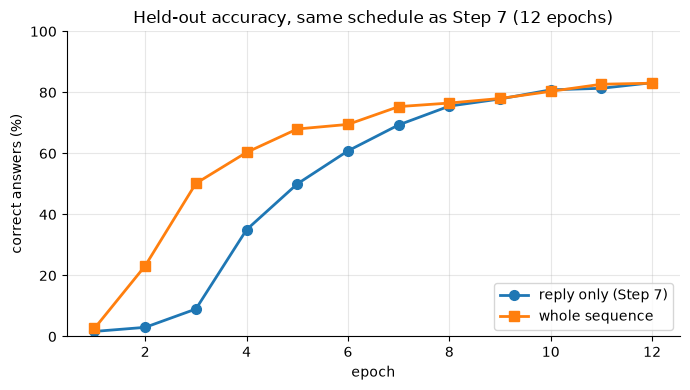

In [15]:
if run_ablation:
    fig, ax = plt.subplots(figsize=(7, 4))
    epochs_done = range(1, epochs + 1)
    ax.plot(epochs_done, [100 * a for a in accuracy_history], linewidth=2, marker="o", markersize=7, label="reply only (Step 7)")
    ax.plot(epochs_done, [100 * a for a in whole_sequence_history], linewidth=2, marker="s", markersize=7, label="whole sequence")
    ax.set_xlabel("epoch")
    ax.set_ylabel("correct answers (%)")
    ax.set_ylim(0, 100)
    ax.set_title(f"Held-out accuracy, same schedule as Step 7 ({epochs} epochs)")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

- **Same schedule as Step 7 (12 epochs).** Scoring the whole sequence makes the jump much earlier: 23.2% after epoch 2 and 50.2% after epoch 3, against 3.0% and 9.0% when only the reply is scored. The reply-only model catches up from epoch 8 on, and both end at the same accuracy: 83.2% with reply-only scoring and 83.0% with whole-sequence scoring. That difference is far below the sampling noise of about 1.6 percentage points.
- **Shorter schedule (4 epochs).** The picture is the same. After 4 epochs the whole-sequence model answers 64.0% of the held-out questions correctly and the reply-only model 40.0%. With only 4 epochs, the reply-only model has just started its jump when the learning rate is already small.

**What this means.** We had expected scoring only the reply to help: the digits of a question are random, and the question is the same in the positive and the negative, so scoring it seemed to add only noise. That expectation was wrong, or at least much less important than something we had not considered. One likely explanation is that the questions are worth learning too, because they carry arithmetic structure. In `3744/78=?` the first number is always a multiple of the second, and in `x*62=6076,x=?` the right-hand side is always a multiple of 62. Predicting the characters of a question is therefore extra practice with the same number patterns that the answers need. Each comparison is a single run, so we only rely on the large, consistent difference: in both schedules, whole-sequence scoring learns faster, and it is never behind by more than the sampling noise.

## Summary

- **Task 1.** 100,201 positive-negative pairs over 12 question types with numbers from 0–100, plus 600 held-out questions. The positives follow the wording of the sample file. The negatives are the pretrained model's own replies, almost all refusals, generated in batches: 22 minutes instead of about 3 hours.
- **Task 2.** DPO with the template's loss (preference term plus SFT term), scoring only the reply, AdamW with a cosine schedule, learning rate `1e-3` and 12 epochs: 86 minutes on an Apple M2 Pro. The model learns the reply format within the first epoch, and the arithmetic only from the fourth epoch on.
- **Task 3.** 7 of the 8 printed test replies are correct; the eighth is a sampling slip on a question the model answered correctly just before. On the 600 held-out questions the model is right 80.3% of the time: every addition and subtraction, 78.5% of the divisions, and 25% of the multiplications (14% when both factors have two digits).
- **Ablation.** Scoring only the reply, which we expected to help, does not. With the same settings, the template's whole-sequence scoring makes the jump one to two epochs earlier and ends at the same 83%.
- **Weak point and next step.** Multiplying two 2-digit numbers in one go is the weak point. Lee et al. (2023) found that small transformers multiply much better when the working shows intermediate steps, such as partial products. That would change the reply format given in the sample file, so we kept the sample wording.

## References

- A. Karpathy, *nanoGPT*, https://github.com/karpathy/nanoGPT. `model.py` and `configurator.py` come from this repository and are not modified.
- Course base code, https://github.com/zhouyuan888888/NanoGPT-Math. It provides the pretrained model `sft/gpt.pt`, the character codebook `sft/meta.pkl`, the sample `pos_neg_pairs.json`, and the template notebook: the code of Steps 1–4 (Step 2 with the changes listed there), `compute_logprob`, `pad_or_truncate`, `get_batches`, the skeletons of Steps 7 and 8, and the suggested loss.
- R. Rafailov, A. Sharma, E. Mitchell, S. Ermon, C. D. Manning, C. Finn, "Direct Preference Optimization: Your Language Model is Secretly a Reward Model", NeurIPS 2023, https://arxiv.org/abs/2305.18290.
- N. Lee, K. Sreenivasan, J. D. Lee, K. Lee, D. Papailiopoulos, "Teaching Arithmetic to Small Transformers", ICLR 2024, https://arxiv.org/abs/2307.03381.
- PyTorch documentation for `torch.optim.AdamW`, `torch.optim.lr_scheduler.CosineAnnealingLR`, `torch.nn.utils.clip_grad_norm_` and `torch.mps.empty_cache`.

Written for this assignment: the Task 1 cells (the sampling steps in `make_negative` follow `GPT.generate` in `model.py`), the code of Steps 5–7 (including `compute_reply_logprob`), the completion of Step 8 and the held-out evaluation, the ablation, and all explanations.